=== PIXEL TENSOR STATISTICS ===
Original Shape   : (720, 1280, 3)
Preprocessed Shape: (640, 640, 3)
Min Pixel Value  : 0.0000
Max Pixel Value  : 0.4471
Data Type        : float32


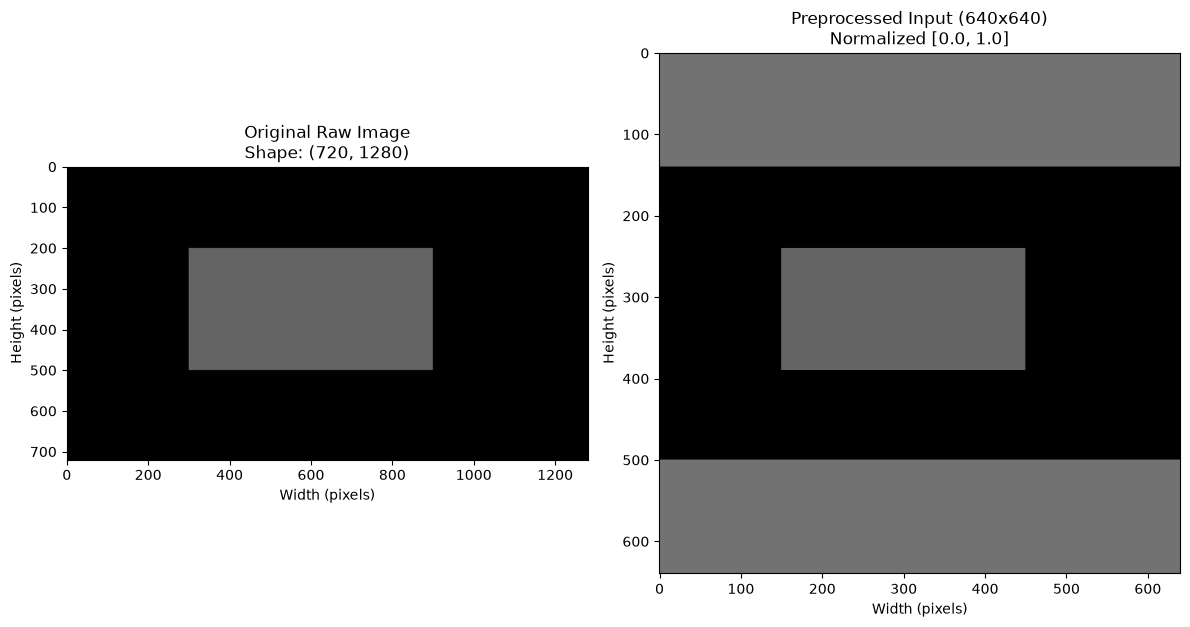

<Figure size 640x480 with 0 Axes>

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Load high-resolution traffic scene image (or generate fallback synthetic image)
img_path = "../data/traffic.jpg"
raw_img = cv2.imread(img_path)

if raw_img is None:
    raw_img = np.zeros((1080, 1920, 3), dtype=np.uint8)
    cv2.rectangle(
        raw_img, (200, 400), (1000, 900), (120, 120, 120), -1
    )  # Road segment
    cv2.rectangle(
        raw_img, (400, 500), (600, 700), (0, 0, 255), -1
    )  # Vehicle representation

# Convert BGR (OpenCV default) to RGB for Matplotlib visualization
rgb_orig = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)

# 2. Resize image to standard 640x640 using aspect-ratio letterboxing
target_size = (640, 640)
h, w = raw_img.shape[:2]
scale = min(target_size[0] / h, target_size[1] / w)
new_w, new_h = int(w * scale), int(h * scale)

resized = cv2.resize(raw_img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

# Letterbox padding to reach exact 640x640 dimensions
top = (target_size[0] - new_h) // 2
bottom = target_size[0] - new_h - top
left = (target_size[1] - new_w) // 2
right = target_size[1] - new_w - left

letterboxed = cv2.copyMakeBorder(
    resized,
    top,
    bottom,
    left,
    right,
    cv2.BORDER_CONSTANT,
    value=[114, 114, 114],
)

# 3. Normalize pixel values from [0, 255] to floating-point [0.0, 1.0]
normalized_tensor = letterboxed.astype(np.float32) / 255.0

# Print pixel tensor statistics
print("=== PIXEL TENSOR STATISTICS ===")
print(f"Original Shape   : {raw_img.shape}")
print(f"Preprocessed Shape: {normalized_tensor.shape}")
print(f"Min Pixel Value  : {normalized_tensor.min():.4f}")
print(f"Max Pixel Value  : {normalized_tensor.max():.4f}")
print(f"Data Type        : {normalized_tensor.dtype}")

# 4. Display original and preprocessed images side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(rgb_orig)
axes[0].set_title(f"Original Raw Image\nShape: {raw_img.shape[:2]}")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")

rgb_preprocessed = cv2.cvtColor(letterboxed, cv2.COLOR_BGR2RGB)
axes[1].imshow(rgb_preprocessed)
axes[1].set_title(f"Preprocessed Input (640x640)\nNormalized [0.0, 1.0]")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

plt.tight_layout()
plt.show()
axes[1].set_ylabel("Height (pixels)")

plt.tight_layout()
plt.show()

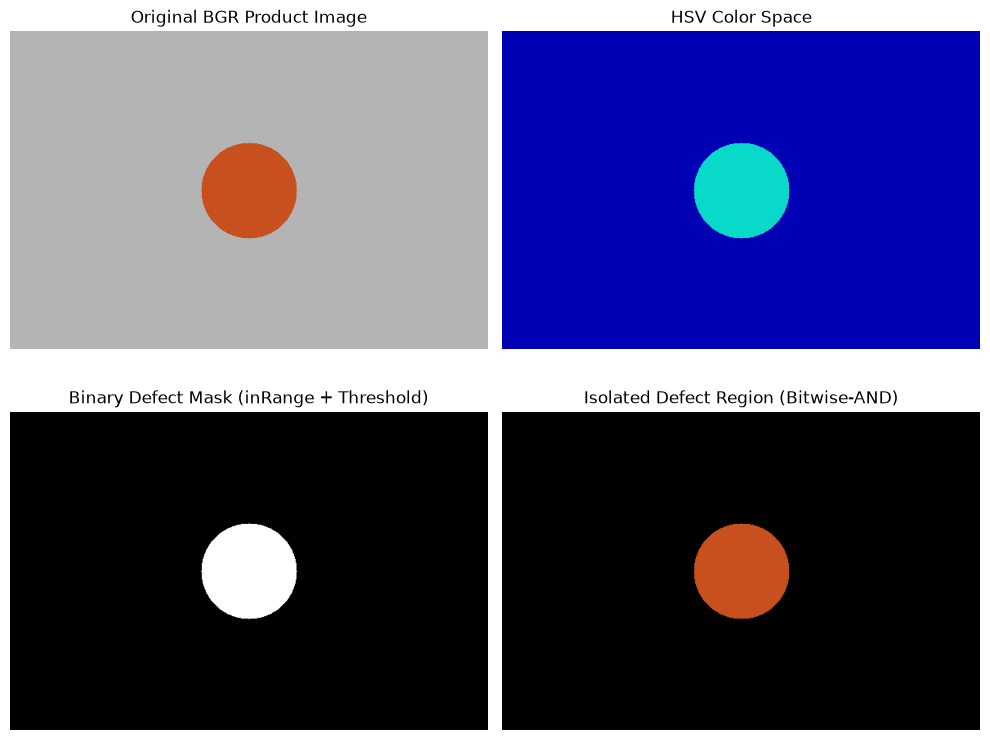

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate/Load sample industrial product image with a defect target
industrial_img = np.zeros((400, 600, 3), dtype=np.uint8)
industrial_img[:, :] = [180, 180, 180]  # Metallic silver background

# Draw defect area (rust/copper hue in BGR)
cv2.circle(industrial_img, (300, 200), 60, (30, 80, 200), -1)

# Convert BGR to HSV and LAB color spaces
hsv_img = cv2.cvtColor(industrial_img, cv2.COLOR_BGR2HSV)
lab_img = cv2.cvtColor(industrial_img, cv2.COLOR_BGR2LAB)

# 2. Define HSV bounds for defect region isolation (Rust / Orange-Red hues)
lower_hsv = np.array([5, 100, 100])
upper_hsv = np.array([25, 255, 255])

# 3. Apply binary threshold mask using cv2.inRange and refine with threshold
inrange_mask = cv2.inRange(hsv_img, lower_hsv, upper_hsv)
_, binary_mask = cv2.threshold(inrange_mask, 127, 255, cv2.THRESH_BINARY)

# 4. Bitwise-AND mask with original image to isolate defect regions
isolated_defect = cv2.bitwise_and(
    industrial_img, industrial_img, mask=binary_mask
)

# Visualize all stages in a Matplotlib Grid
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(cv2.cvtColor(industrial_img, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original BGR Product Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(hsv_img)
axes[0, 1].set_title("HSV Color Space")
axes[0, 1].axis("off")

axes[1, 0].imshow(binary_mask, cmap="gray")
axes[1, 0].set_title("Binary Defect Mask (inRange + Threshold)")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.cvtColor(isolated_defect, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Isolated Defect Region (Bitwise-AND)")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


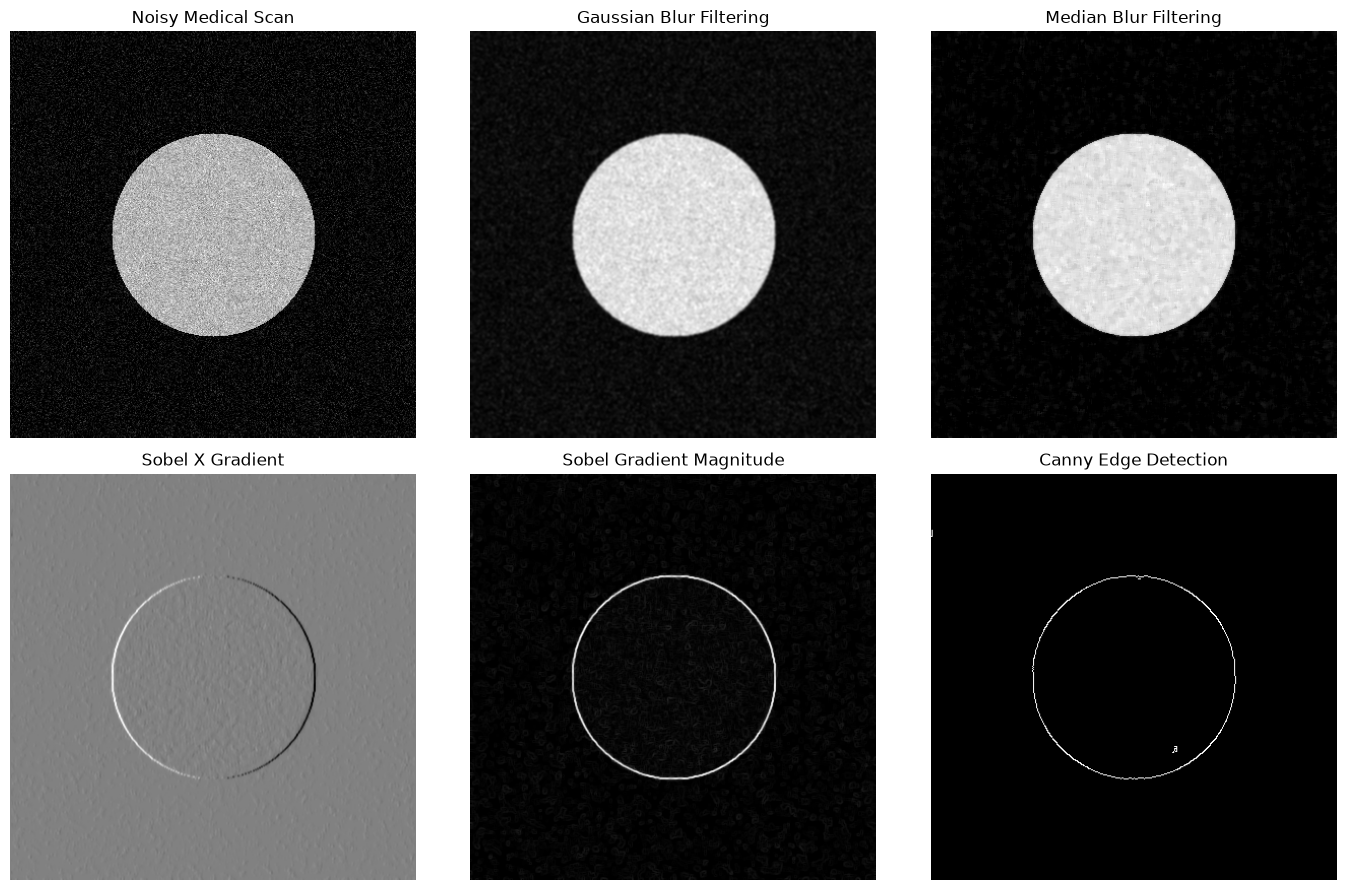

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Create/Load grayscale medical scan image with synthetic noise
clean_medical = np.zeros((400, 400), dtype=np.uint8)
cv2.circle(clean_medical, (200, 200), 100, 180, -1)  # Synthetic organ structure

# Add synthetic Gaussian noise
noise = np.random.normal(0, 25, clean_medical.shape).astype(np.int16)
noisy_medical = np.clip(clean_medical.astype(np.int16) + noise, 0, 255).astype(
    np.uint8
)

# 2. Compare Gaussian Blurring vs. Median Filtering
gauss_blur = cv2.GaussianBlur(noisy_medical, (5, 5), 0)
median_blur = cv2.medianBlur(noisy_medical, 5)

# 3. Perform Sobel Edge Detection along X and Y axes on median filtered image
sobelx = cv2.Sobel(median_blur, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(median_blur, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobelx, sobely)
sobel_magnitude = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U
)

# 4. Apply Canny Edge Detection with tuned hysteresis thresholds
canny_edges = cv2.Canny(median_blur, threshold1=50, threshold2=150)

# Quantitative comparison grid visualization
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(noisy_medical, cmap="gray")
axes[0, 0].set_title("Noisy Medical Scan")
axes[0, 0].axis("off")

axes[0, 1].imshow(gauss_blur, cmap="gray")
axes[0, 1].set_title("Gaussian Blur Filtering")
axes[0, 1].axis("off")

axes[0, 2].imshow(median_blur, cmap="gray")
axes[0, 2].set_title("Median Blur Filtering")
axes[0, 2].axis("off")

axes[1, 0].imshow(sobelx, cmap="gray")
axes[1, 0].set_title("Sobel X Gradient")
axes[1, 0].axis("off")

axes[1, 1].imshow(sobel_magnitude, cmap="gray")
axes[1, 1].set_title("Sobel Gradient Magnitude")
axes[1, 1].axis("off")

axes[1, 2].imshow(canny_edges, cmap="gray")
axes[1, 2].set_title("Canny Edge Detection")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()